In [ ]:
import os
os.chdir("/content")

In [ ]:
!rm -rf /content/Data
!git clone https://github.com/KU-EBL/Data.git

In [ ]:
import os
os.chdir("/content/Data/EDS")
os.listdir()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
)

In [ ]:
df = pd.read_csv("gb_classifier_algae_practice_data.csv")
display(df.head())
print("Shape:", df.shape)
print(df.dtypes)

,Sample_ID,Season,Site_type,Extreme_Temperature,Flow_m3_s,Water_Temperature_C,pH,DO_mg_L,Turbidity_NTU,TN_mg_L,TP_mg_L,Rainfall_7d_mm,Algae_Bloom
0,S001,Summer,Agricultural stream,Yes,9.47,25.34,7.18,NaN,6.72,2.83,0.178,8.59,Yes
1,S002,Winter,Reservoir,No,3.76,7.08,7.88,8.52,22.83,2.22,0.033,20.35,No
2,S003,Autumn,Reservoir,No,5.68,22.64,7.53,6.20,10.87,2.33,0.124,16.78,No
3,S004,Summer,Urban stream,Yes,10.57,32.70,7.62,4.81,15.36,0.93,0.023,39.77,No
4,S005,Spring,Wetland,No,6.54,21.31,7.37,5.33,9.45,2.53,0.184,20.07,No


Shape: (320, 13)
Sample_ID               object
Season                  object
Site_type               object
Extreme_Temperature     object
Flow_m3_s              float64
Water_Temperature_C    float64
pH                     float64
DO_mg_L                float64
Turbidity_NTU          float64
TN_mg_L                float64
TP_mg_L                float64
Rainfall_7d_mm         float64
Algae_Bloom             object
dtype: object


In [ ]:
print("\nMissing values in the original dataset")
print(df.isnull().sum())


Missing values in the original dataset
Sample_ID              0
Season                 0
Site_type              0
Extreme_Temperature    0
Flow_m3_s              7
Water_Temperature_C    5
pH                     6
DO_mg_L                8
Turbidity_NTU          9
TN_mg_L                7
TP_mg_L                6
Rainfall_7d_mm         6
Algae_Bloom            0
dtype: int64


In [ ]:
print(df["Algae_Bloom"].value_counts())

Algae_Bloom
No     239
Yes     81
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=["Sample_ID", "Algae_Bloom"])
y = df["Algae_Bloom"].map({"No": 0, "Yes": 1})

numeric_features = [
    "Flow_m3_s",
    "Water_Temperature_C",
    "pH",
    "DO_mg_L",
    "Turbidity_NTU",
    "TN_mg_L",
    "TP_mg_L",
    "Rainfall_7d_mm",
]

categorical_features = [
    "Season",
    "Site_type",
    "Extreme_Temperature",
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42,
)

In [ ]:
numeric_imputer = SimpleImputer(
    strategy="median"
)

# Learn median values from the training data
X_train_numeric = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

# Apply the same median values to the test data
X_test_numeric = numeric_imputer.transform(
    X_test[numeric_features]
)

In [ ]:
X_train_numeric = pd.DataFrame(
    X_train_numeric,
    columns=numeric_features,
    index=X_train.index
)

X_test_numeric = pd.DataFrame(
    X_test_numeric,
    columns=numeric_features,
    index=X_test.index
)

In [ ]:
# Create the categorical imputer
categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

# Learn the most frequent categories from the training data
X_train_categorical = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

# Apply the same categories to the test data
X_test_categorical = categorical_imputer.transform(
    X_test[categorical_features]
)

In [ ]:
X_train_categorical = pd.DataFrame(
    X_train_categorical,
    columns=categorical_features,
    index=X_train.index
)

X_test_categorical = pd.DataFrame(
    X_test_categorical,
    columns=categorical_features,
    index=X_test.index
)

In [ ]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn categories from the training data
X_train_encoded = encoder.fit_transform(
    X_train_categorical
)

# Apply the same encoding rules to the test data
X_test_encoded = encoder.transform(
    X_test_categorical
)

In [ ]:
encoded_feature_names = encoder.get_feature_names_out(
    categorical_features
)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_feature_names,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_feature_names,
    index=X_test.index
)

In [ ]:
X_train_final = pd.concat(
    [
        X_train_numeric,
        X_train_encoded
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test_numeric,
        X_test_encoded
    ],
    axis=1
)

In [ ]:
print("Processed training data")
display(X_train_final.head())

print("Processed test data")
display(X_test_final.head())

print("Training shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

print("Missing values in training data:",
      X_train_final.isnull().sum().sum())

print("Missing values in test data:",
      X_test_final.isnull().sum().sum())

Processed training data


,Flow_m3_s,Water_Temperature_C,pH,DO_mg_L,Turbidity_NTU,TN_mg_L,TP_mg_L,Rainfall_7d_mm,Season_Autumn,Season_Spring,Season_Summer,Season_Winter,Site_type_Agricultural stream,Site_type_Reservoir,Site_type_Urban stream,Site_type_Wetland,Extreme_Temperature_No,Extreme_Temperature_Yes
11,2.75,7.73,7.01,6.61,21.27,3.00,0.152,17.84,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
218,12.33,10.44,7.96,8.49,13.95,2.20,0.219,18.25,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
61,5.18,26.69,8.31,5.34,8.89,1.79,0.116,0.70,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
208,9.90,19.95,6.85,6.38,10.59,2.54,0.183,13.53,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
207,16.45,22.40,8.20,8.36,4.31,0.51,0.041,12.34,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


Processed test data


,Flow_m3_s,Water_Temperature_C,pH,DO_mg_L,Turbidity_NTU,TN_mg_L,TP_mg_L,Rainfall_7d_mm,Season_Autumn,Season_Spring,Season_Summer,Season_Winter,Site_type_Agricultural stream,Site_type_Reservoir,Site_type_Urban stream,Site_type_Wetland,Extreme_Temperature_No,Extreme_Temperature_Yes
126,1.01,22.59,7.97,5.88,11.82,1.92,0.126,13.09,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
36,5.95,27.70,7.58,4.30,8.02,3.37,0.131,12.50,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
173,10.54,19.13,7.46,6.70,16.95,1.84,0.075,14.13,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
302,7.69,28.88,7.37,4.66,21.74,2.51,0.177,25.55,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
157,12.36,12.46,7.34,5.28,32.52,1.54,0.173,25.75,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Training shape: (240, 18)
Test shape: (80, 18)
Missing values in training data: 0
Missing values in test data: 0


In [ ]:
baseline_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=5,
    subsample=1.0,
    random_state=42
)

baseline_model.fit(
    X_train_final,
    y_train
)

y_pred = baseline_model.predict(X_test_final)
y_prob = baseline_model.predict_proba(X_test_final)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

Accuracy : 0.838
Precision: 0.684
Recall   : 0.65
F1-score : 0.667
ROC-AUC  : 0.878


In [ ]:
print("\nConfusion matrix")
print(confusion_matrix(y_test, y_pred))


Confusion matrix
[[54  6]
 [ 7 13]]


In [ ]:
print("\nClassification report")
print(classification_report(y_test, y_pred, target_names=["No bloom", "Bloom"]))


Classification report
              precision    recall  f1-score   support

    No bloom       0.89      0.90      0.89        60
       Bloom       0.68      0.65      0.67        20

    accuracy                           0.84        80
   macro avg       0.78      0.78      0.78        80
weighted avg       0.83      0.84      0.84        80



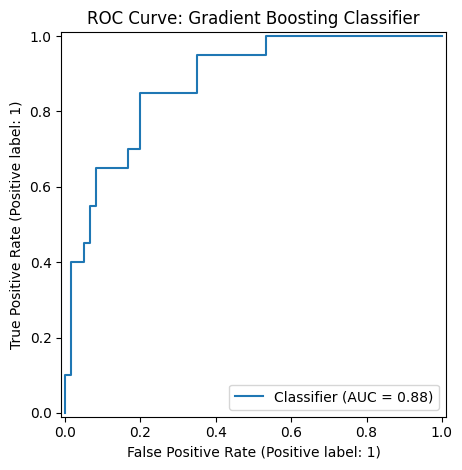

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve: Gradient Boosting Classifier")
plt.tight_layout()
plt.show()